<a href="https://colab.research.google.com/github/Defani/Shannon-Wienner-Index-Analysis-for-Mackinnon-Bird-Method/blob/main/Shannon_Wienner.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Perhitungan Indeks Keanekaragaman Shannon-Wiener (H') Berbasis Metode Daftar Jenis Mackinnon Menggunakan Program R**

# *Praktik menggunakan library vegan*


**Oleh : Defani Arman Alfitriansyan**

## **Pengertian**  
Indeks Shannon-Wiener ($H'$) digunakan untuk mengukur keanekaragaman hayati suatu komunitas.  
Indeks ini mempertimbangkan jumlah jenis (richness) dan proporsi relatif tiap jenis (evenness).  
Semakin tinggi nilai $H'$, semakin beragam komunitas tersebut.

---

## **Rumus**

$$
H' = - \sum_{i=1}^{S} p_i \ln(p_i)
$$

Keterangan:
- $H'$ = Indeks keanekaragaman Shannon-Wiener  
- $S$ = Jumlah total jenis (species richness)  
- $p_i$ = Proporsi individu jenis ke-i terhadap total individu  
- $\ln$ = Logaritma natural (basis e)

---



## **Interpretasi Umum Nilai $H'$**

| Nilai $H'$ | Kriteria Keanekaragaman |
|-------------|------------------------|
| < 1.0 | Rendah (komunitas didominasi sedikit jenis) |
| 1.0 – 3.0 | Sedang (keanekaragaman cukup stabil) |
| > 3.0 | Tinggi (komunitas beragam dan seimbang) |

---





**1. Import dan install Library**

In [ ]:
#install
install.packages("dplyr")
install.packages("readxl")
install.packages("vegan")
install.packages("ggplot2")


Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)



In [ ]:

library(readxl)
library(dplyr)
library(vegan)
library(ggplot2)

In [ ]:
# 2. BACA SEMUA SHEET DARI FILE EXCEL
file <- "data_burung_defani.xlsx"
sheets <- excel_sheets(file)

data_list <- lapply(sheets, function(x) read_excel(file, sheet = x))


In [ ]:
#3. TAMPILKAN DATA PER SHEET (DAFTAR)
for (i in 1:length(sheets)) {
  cat("\n==============================\n")
  cat("Daftar:", sheets[i], "\n")
  cat("==============================\n")
  print(data_list[[i]])
}



Daftar: Daftar_1 
# A tibble: 10 × 4
   Lokasi       Daftar Nama_Ilmiah            Jumlah
   <chr>         <dbl> <chr>                   <dbl>
 1 Leuwung Gede      1 Copsychus saularis         11
 2 Leuwung Gede      1 Acridotheres javanicus      3
 3 Leuwung Gede      1 Nisaetus bartelsii          3
 4 Leuwung Gede      1 Acridotheres javanicus      7
 5 Leuwung Gede      1 Orthotomus sutorius        12
 6 Leuwung Gede      1 Copsychus saularis         10
 7 Leuwung Gede      1 Egretta garzetta            2
 8 Leuwung Gede      1 Pycnonotus aurigaster       9
 9 Leuwung Gede      1 Collocalia esculenta        6
10 Leuwung Gede      1 Gallus gallus               4

Daftar: Daftar_2 
# A tibble: 10 × 4
   Lokasi       Daftar Nama_Ilmiah            Jumlah
   <chr>         <dbl> <chr>                   <dbl>
 1 Leuwung Gede      2 Collocalia esculenta        8
 2 Leuwung Gede      2 Collocalia vulcannorum      1
 3 Leuwung Gede      2 Halcyon chloris             3
 4 Leuwung Gede      2 

In [ ]:
#4. GABUNG SEMUA SHEET JADI SATU DATASET
data_all <- bind_rows(data_list)

In [ ]:
# 5. HITUNG JUMLAH INDIVIDU PER JENIS
data_sum <- data_all %>%
  group_by(Nama_Ilmiah) %>%
  summarise(Jumlah = sum(Jumlah, na.rm = TRUE)) %>%
  arrange(desc(Jumlah))

print(data_sum)

# A tibble: 15 × 2
   Nama_Ilmiah              Jumlah
   <chr>                     <dbl>
 1 Copsychus saularis          126
 2 Acridotheres javanicus       99
 3 Orthotomus sutorius          92
 4 Collocalia esculenta         82
 5 Egretta garzetta             81
 6 Pycnonotus aurigaster        65
 7 Nisaetus bartelsii           38
 8 Gallus gallus                36
 9 Halcyon chloris              23
10 Lonchura leucogastroides     13
11 Dicrurus macrocercus         12
12 Gallus varius                10
13 Otus sp                       5
14 Collocalia vulcannorum        1
15 Lonchura maja                 1


In [ ]:
# 6. HITUNG JUMLAH JENIS PER DAFTAR
jenis_per_daftar <- data_all %>%
  group_by(Daftar) %>%
  summarise(Jumlah_Jenis = n_distinct(Nama_Ilmiah))

print(jenis_per_daftar)

# A tibble: 10 × 2
   Daftar Jumlah_Jenis
    <dbl>        <int>
 1      1            8
 2      2            8
 3      3            7
 4      4            8
 5      5            8
 6      6            8
 7      7            8
 8      8            8
 9      9            8
10     10            8


In [ ]:
#7. HITUNG KUMULATIF JENIS UNTUK SETIAP DAFTAR
jenis_kumulatif <- jenis_per_daftar %>%
  mutate(Kumulatif_Jenis = cumsum(Jumlah_Jenis))

print(jenis_kumulatif)


# A tibble: 10 × 3
   Daftar Jumlah_Jenis Kumulatif_Jenis
    <dbl>        <int>           <int>
 1      1            8               8
 2      2            8              16
 3      3            7              23
 4      4            8              31
 5      5            8              39
 6      6            8              47
 7      7            8              55
 8      8            8              63
 9      9            8              71
10     10            8              79


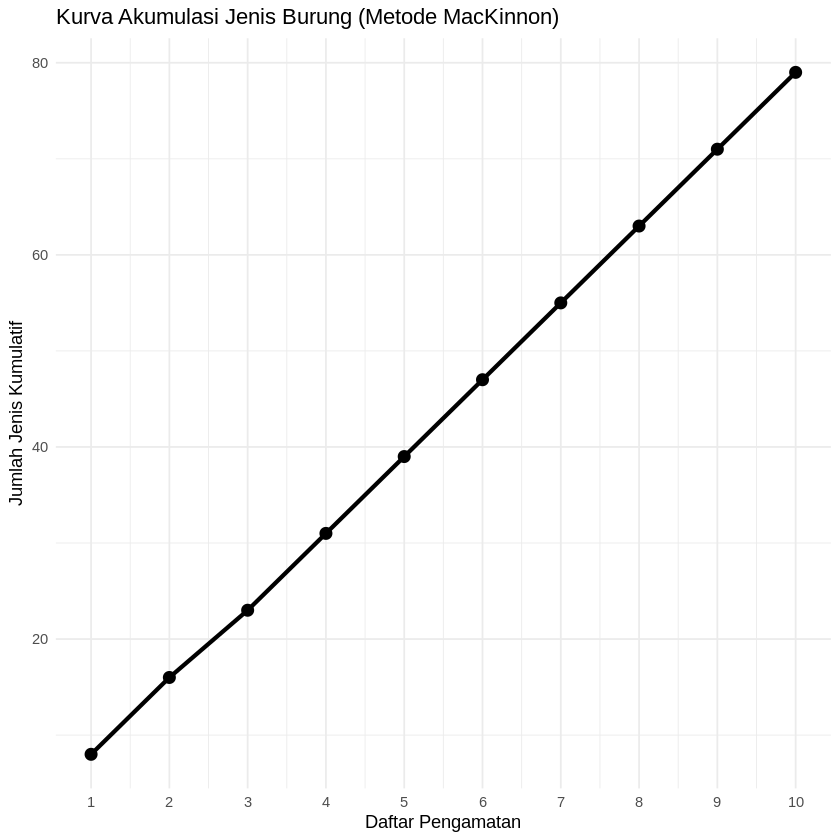

In [ ]:
# 8. PLOT KURVA AKUMULASI JENIS (METODE MACKINNON)
ggplot(jenis_kumulatif, aes(x = Daftar, y = Kumulatif_Jenis)) +
  geom_line(linewidth = 1.2) +
  geom_point(size = 3) +
  scale_x_continuous(breaks = 1:10) +
  theme_minimal() +
  labs(
    title = "Kurva Akumulasi Jenis Burung (Metode MacKinnon)",
    x = "Daftar Pengamatan",
    y = "Jumlah Jenis Kumulatif"
  )


In [ ]:
# 9. HITUNG INDEKS KEANEKARAGAMAN SHANNON–WIENER (H')
p_i <- data_sum$Jumlah / sum(data_sum$Jumlah)
H <- -sum(p_i * log(p_i))

cat("\nIndeks Keanekaragaman Shannon-Wiener (H') =", H, "\n")



Indeks Keanekaragaman Shannon-Wiener (H') = 2.284512 


In [ ]:
# KLASIFIKASI TINGKAT KEANEKARAGAMAN
kategori <- ifelse(
  H < 1, "Rendah",
  ifelse(H < 3, "Sedang", "Tinggi")
)

cat("Kategori Keanekaragaman:", kategori, "\n")

Kategori Keanekaragaman: Sedang 


**Referensi**


1. Krebs, C. J. (1999). Ecological Methodology (2nd ed.). Menlo Park, CA: Benjamin/Cummings.

2. Magurran, A. E. (2004). Measuring Biological Diversity. Oxford: Blackwell Publishing.

3. Odum, E. P., & Barrett, G. W. (2005). Fundamentals of Ecology (5th ed.). Belmont, CA: Thomson Brooks/Cole.

4. Oksanen, F.J., et al. (2017) Vegan: Community Ecology Package. R package Version 2.4-3.
https://CRAN.R-project.org/package=vegan

5. Shannon, C. E., & Weaver, W. (1949). The Mathematical Theory of Communication. Urbana, IL: University of Illinois Press.

6. Whittaker, R. H. (1972). Evolution and measurement of species diversity. Taxon, 21(2–3), 213–251. https://doi.org/10.2307/1218190





